In [2]:
import io, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import holidays
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

DATA_DIR, FIG_DIR = Path("data"), Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

In [3]:
# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------
START, END = "2024-01-01", "2026-10-31"   
TEST_MONTHS = 12                          
SUCCESS_THRESHOLD_PCT = 10.0              
BALANCE_TEMP_C = 18.0                     
REFRESH = False                           

BCH_DATA_START_ROW = 5         # rows 0-4 of each .xls are header/metadata
BCH_TZ = "America/Vancouver"   
BCH_HOUR_ENDING = False        
BCH_DATETIME_COL = None        
BCH_LOAD_COL = None            

# Environment Canada cross-check (one station, one year)
ECCC_STATION_ID = 51442
ECCC_YEAR = 2024


CITIES = {
    "Vancouver":     dict(lat=49.2827, lon=-123.1207, pop=2_642_825),
    "Victoria":      dict(lat=48.4284, lon=-123.3656, pop=397_237),
    "Kelowna":       dict(lat=49.8880, lon=-119.4960, pop=222_162),
    "Kamloops":      dict(lat=50.6745, lon=-120.3273, pop=114_142),
    "Prince George": dict(lat=53.9171, lon=-122.7497, pop=89_490),
}

START_TS = pd.Timestamp(START, tz="UTC")
END_TS = pd.Timestamp(END, tz="UTC") + pd.Timedelta(hours=23)
TEST_START = (pd.Timestamp(END, tz="UTC") - pd.DateOffset(months=TEST_MONTHS) + pd.Timedelta(days=1)).normalize()
print(f"Study window: {START} to {END} | test period starts {TEST_START.date()}")


def http_get(url, params=None, retries=4, timeout=90):
    """GET with simple backoff on rate limiting (HTTP 429)."""
    r = None
    for i in range(retries):
        r = requests.get(url, params=params, timeout=timeout,
                         headers={"User-Agent": "bc-load-viability-notebook/0.1"})
        if r.status_code == 429:
            time.sleep(5 * (i + 1))
            continue
        r.raise_for_status()
        return r
    r.raise_for_status()
    return r


def audit_row(s, name, resolution="1h"):
    """Coverage summary for a time-indexed series."""
    s = s.sort_index()
    full = pd.date_range(s.index.min(), s.index.max(), freq=resolution)
    present = s.reindex(full).notna().sum()
    return dict(source=name, start=s.index.min().date(), end=s.index.max().date(),
                rows=int(s.notna().sum()), expected=len(full),
                missing_pct=round(100 * (1 - present / len(full)), 2))

Study window: 2024-01-01 to 2026-10-31 | test period starts 2025-11-01


## 1. BC Hydro balancing authority load (target variable)

BC Hydro publishes **gross telemetered load** for the BC Balancing Authority as yearly Excel files (hourly), listed on its *Historical Transmission Data* page. The files are `.xls`, so `xlrd` is required.

Each file has a header block in rows 0-4, and data starts at row index 5 (`BCH_DATA_START_ROW`). The parser reads the header text of every column across those five rows to find the timestamp, load, and (if present) separate hour columns, then validates the choices against the data. **Read the raw preview below once**; if detection picks the wrong columns, set `BCH_DATETIME_COL` / `BCH_LOAD_COL` to column positions (0, 1, 2, ...).

In [4]:
BCH_BASE = ("https://www.bchydro.com/content/dam/BCHydro/customer-portal/documents/corporate/"
            "suppliers/transmission-system/balancing_authority_load_data/")

def bchydro_url(year):
    """URL patterns taken from BC Hydro's Historical Transmission Data page (2015 onward)."""
    if year == 2026:
        return BCH_BASE + "BalancingAuthorityLoad 2026.xls"
    if year in (2024, 2025):
        return BCH_BASE + f"Historical Transmission Data/BalancingAuthorityLoad {year}.xls"
    return BCH_BASE + f"Historical Transmission Data/BalancingAuthorityLoad{year}.xls"


def download_bchydro(year):
    path = DATA_DIR / f"bchydro_BA_load_{year}.xls"
    # the current year's file is updated as the year progresses, so always refresh it
    if REFRESH or not path.exists() or year == pd.Timestamp(END).year:
        r = http_get(bchydro_url(year))
        path.write_bytes(r.content)
    return path


def _pick(header_text, keys, exclude=()):
    """First column whose header text (all header rows combined) contains one of the keys."""
    for j, t in header_text.items():
        if j not in exclude and any(k in t for k in keys):
            return j
    return None


def parse_bchydro(path):
    raw = pd.read_excel(path, header=None)
    top, data = raw.iloc[:BCH_DATA_START_ROW], raw.iloc[BCH_DATA_START_ROW:].copy()

    # Header text per column, combined across all header rows (robust to multi-row headers)
    header_text = {j: " ".join(str(v) for v in top[j].tolist() if pd.notna(v)).lower() for j in raw.columns}

    dt_col = BCH_DATETIME_COL if BCH_DATETIME_COL is not None else _pick(header_text, ("date", "time"))
    load_col = BCH_LOAD_COL if BCH_LOAD_COL is not None else _pick(header_text, ("load", "mw"), exclude=(dt_col,))
    hr_col = next((j for j, t in header_text.items()
                   if j not in (dt_col, load_col) and ("hour" in t or {"he", "hr", "hb"} & set(t.split()))), None)
    if dt_col is None or load_col is None:
        raise ValueError(f"Could not identify columns in {path.name}. Header rows:\n{top}\n"
                         "Set BCH_DATETIME_COL and BCH_LOAD_COL (column positions) in the config.")

    ts = pd.to_datetime(data[dt_col], errors="coerce")
    if ts.notna().mean() < 0.9:
        raise ValueError(f"Column {dt_col} in {path.name} does not look like timestamps. "
                         f"Sample values: {data[dt_col].head(5).tolist()}. Set BCH_DATETIME_COL.")
    if hr_col is not None and ts.dt.hour.nunique(dropna=True) <= 1:
        hrs = pd.to_numeric(data[hr_col], errors="coerce")
        offset = hrs - 1 if hrs.max() == 24 else hrs          # hour-ending 1..24 -> 0..23
        ts = ts.dt.normalize() + pd.to_timedelta(offset, unit="h")
    elif BCH_HOUR_ENDING:
        ts = ts - pd.Timedelta(hours=1)

    vals = pd.to_numeric(data[load_col], errors="coerce")
    if vals.notna().mean() < 0.9:
        raise ValueError(f"Column {load_col} in {path.name} is not numeric. "
                         f"Sample values: {data[load_col].head(5).tolist()}. Set BCH_LOAD_COL.")

    s = pd.Series(vals.values, index=pd.DatetimeIndex(ts))
    s = s[s.index.notna()]
    s.index = s.index.tz_localize(BCH_TZ, ambiguous="NaT", nonexistent="shift_forward")
    s = s[s.index.notna()].tz_convert("UTC")
    s = s.groupby(level=0).mean().sort_index()
    s.name = "load_mw"
    return s, dict(datetime_col=dt_col, load_col=load_col, hour_col=hr_col,
                   header_text={k: v[:40] for k, v in header_text.items() if k in (dt_col, load_col, hr_col)})


frames, first_path = [], None
for y in range(START_TS.year, END_TS.year + 1):
    try:
        p = download_bchydro(y)
        first_path = first_path or p
        s, cols_used = parse_bchydro(p)
        frames.append(s)
        print(f"{y}: {len(s):>6,} rows | columns used: {cols_used}")
    except Exception as e:
        print(f"{y}: FAILED -> {type(e).__name__}: {str(e)[:300]}")

load = pd.concat(frames).sort_index()
load = load[~load.index.duplicated(keep="first")]
load = load[(load.index >= START_TS) & (load.index <= END_TS)]
print(f"\nBC Hydro load: {load.index.min()} -> {load.index.max()}, {len(load):,} hourly rows")

print("\nRaw preview of the first file (rows 0-4 = header block, data starts at row 5):")
display(pd.read_excel(first_path, header=None).head(8))

2024:  8,780 rows | columns used: {'datetime_col': 0, 'load_col': 2, 'hour_col': 1, 'header_text': {0: 'hourly control area load report date ran', 1: '-2024 bcha he 1', 2: 'control area load 7105'}}
2025:  8,756 rows | columns used: {'datetime_col': 0, 'load_col': 2, 'hour_col': 1, 'header_text': {0: 'hourly control area load report date ran', 1: '-2025 bcha he 1', 2: 'control area load 7942'}}
2026:  7,293 rows | columns used: {'datetime_col': 0, 'load_col': 2, 'hour_col': 1, 'header_text': {0: 'hourly control area load report date ran', 1: '-2026 bcha he 1', 2: 'control area load 8188'}}

BC Hydro load: 2024-01-01 09:00:00+00:00 -> 2026-10-31 23:00:00+00:00, 24,822 hourly rows

Raw preview of the first file (rows 0-4 = header block, data starts at row 5):


,0,1,2
0,Hourly Control Area Load Report,NaN,NaN
1,Date Range:,-2024,NaN
2,Area Group Name:,BCHA,NaN
3,Date ?,HE,Control Area Load
4,01/01/2024,1,7105
5,01/01/2024,2,7001
6,01/01/2024,3,6900
7,01/01/2024,4,6835


In [5]:
# Time-zone / DST sanity check on the parsed timestamps.
full = pd.date_range(load.index.min(), load.index.max(), freq="h")
missing_hours = full.difference(load.dropna().index)
local_missing = missing_hours.tz_convert("America/Vancouver")
print(f"Missing hourly timestamps: {len(missing_hours)} of {len(full):,}")
print("Missing by month of local time. About 1 hour per November is expected (the repeated fall-back hour is dropped);")
print("clusters in March or many more in November suggest the BC Hydro timestamps use a different time convention (try BCH_TZ = 'Etc/GMT+8').")
print(pd.Series(local_missing.month).value_counts().sort_index().to_string())

# Sanity range check on values
print("\nLoad summary (MW):")
print(load.describe().round(0).to_string())

Missing hourly timestamps: 9 of 24,831
Missing by month of local time. About 1 hour per November is expected (the repeated fall-back hour is dropped);
clusters in March or many more in November suggest the BC Hydro timestamps use a different time convention (try BCH_TZ = 'Etc/GMT+8').
1     2
3     3
11    4

Load summary (MW):
count    24822.0
mean      7596.0
std       1129.0
min       5303.0
25%       6862.0
50%       7491.0
75%       8330.0
max      12334.0


## 2. Open-Meteo weather: reanalysis ("observed" proxy)

The **Historical Weather API** (ERA5-based reanalysis) is used as the observed-weather series for training. It is fetched for each of five population centres and combined into a single **population-weighted** series

In [6]:
OM_ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
OM_HISTFC = "https://historical-forecast-api.open-meteo.com/v1/forecast"
WX_VARS = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "shortwave_radiation"]


def om_hourly(url, lat, lon, start, end, variables):
    params = dict(latitude=lat, longitude=lon, start_date=start, end_date=end,
                  hourly=",".join(variables), timezone="GMT")
    h = http_get(url, params).json()["hourly"]
    df = pd.DataFrame(h)
    df["time"] = pd.to_datetime(df["time"], utc=True)
    return df.set_index("time")


def cached_om(kind, city, url, start, end, variables):
    path = DATA_DIR / f"om_{kind}_{city.replace(' ', '_')}_{start}_{end}.csv"
    if path.exists() and not REFRESH:
        df = pd.read_csv(path, index_col=0)
        df.index = pd.to_datetime(df.index, utc=True)
        return df
    df = om_hourly(url, CITIES[city]["lat"], CITIES[city]["lon"], start, end, variables)
    df.to_csv(path)
    time.sleep(1)           # be polite to the free tier
    return df


def pop_weighted(frames):
    w = pd.Series({c: CITIES[c]["pop"] for c in frames})
    w = w / w.sum()
    return sum(frames[c] * w[c] for c in frames)


end_date = (END_TS - pd.Timedelta(days=0)).strftime("%Y-%m-%d")
wx_city = {}
for c in CITIES:
    wx_city[c] = cached_om("reanalysis", c, OM_ARCHIVE, START, end_date, WX_VARS)
    print(f"{c:<14} {len(wx_city[c]):>7,} rows, temperature missing: {wx_city[c]['temperature_2m'].isna().mean():.2%}")

wx = pop_weighted(wx_city)
wx = wx[(wx.index >= START_TS) & (wx.index <= END_TS)]
print(f"\nPopulation-weighted weather: {wx.index.min()} -> {wx.index.max()}, {len(wx):,} rows")
display(wx.describe().round(1))

Vancouver       24,840 rows, temperature missing: 0.00%
Victoria        24,840 rows, temperature missing: 0.00%
Kelowna         24,840 rows, temperature missing: 0.00%
Kamloops        24,840 rows, temperature missing: 0.00%
Prince George   24,840 rows, temperature missing: 0.00%

Population-weighted weather: 2024-01-01 00:00:00+00:00 -> 2026-10-31 23:00:00+00:00, 24,840 rows


,temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation
count,24840.0,24840.0,24840.0,24840.0
mean,10.9,77.6,8.8,152.7
std,6.7,14.3,4.8,230.1
min,-14.9,22.2,0.2,0.0
25%,5.8,68.3,5.2,0.0
50%,10.4,81.0,8.2,9.3
75%,15.9,89.2,11.8,242.8
max,30.9,99.3,44.7,925.4


## 3. Open-Meteo Historical Forecast API

This is a common failure point for forecast-driven studies, so it is tested first. The probe requests one week of archived forecasts for each January and reports whether data come back. The test-period forecasts are then fetched for all five cities and combined with the same population weights.

In [7]:
van = CITIES["Vancouver"]
probe = []
for y in range(2018, END_TS.year + 1):
    try:
        d = om_hourly(OM_HISTFC, van["lat"], van["lon"], f"{y}-01-15", f"{y}-01-21", ["temperature_2m"])
        cov = float(d["temperature_2m"].notna().mean())
        err = ""
    except Exception as e:
        cov, err = np.nan, f"{type(e).__name__}"
    probe.append(dict(year=y, coverage=round(cov, 3) if cov == cov else None, error=err))
probe = pd.DataFrame(probe)
display(probe)
fc_years = probe.loc[probe.coverage.fillna(0) > 0.95, "year"]
print("Archived forecasts available from about:", int(fc_years.min()) if len(fc_years) else "NOT FOUND")

,year,coverage,error
0,2018,1.0,
1,2019,1.0,
2,2020,1.0,
3,2021,1.0,
4,2022,1.0,
5,2023,1.0,
6,2024,1.0,
7,2025,1.0,
8,2026,1.0,


Archived forecasts available from about: 2018


In [8]:
# Fetch archived forecasts for the TEST period only (all that is needed for RQ2 viability)
fc_start, fc_end = TEST_START.strftime("%Y-%m-%d"), END
fc_city = {}
for c in CITIES:
    try:
        fc_city[c] = cached_om("histfc", c, OM_HISTFC, fc_start, fc_end, WX_VARS)
    except Exception as e:
        print(f"{c}: forecast fetch failed -> {type(e).__name__}: {str(e)[:200]}")

if len(fc_city) == len(CITIES):
    wx_fc = pop_weighted(fc_city)
    wx_fc = wx_fc[(wx_fc.index >= TEST_START) & (wx_fc.index <= END_TS)]
    cov = wx_fc["temperature_2m"].notna().mean()
    print(f"Archived forecasts (test period): {wx_fc.index.min()} -> {wx_fc.index.max()}, "
          f"temperature coverage {cov:.1%}")
else:
    wx_fc = None
    print("Forecast-driven experiment will be skipped: not all cities returned forecast data.")

Archived forecasts (test period): 2025-11-01 00:00:00+00:00 -> 2026-10-31 23:00:00+00:00, temperature coverage 100.0%


## 4. Data Check

In [9]:
audit = [audit_row(load, "BC Hydro BA load (hourly, MW)"),
         audit_row(wx["temperature_2m"], "Open-Meteo reanalysis, pop-weighted (hourly)")]
if wx_fc is not None:
    audit.append(audit_row(wx_fc["temperature_2m"], "Open-Meteo archived forecast, test period (hourly)"))
audit_df = pd.DataFrame(audit)
audit_df.to_csv("data_audit.csv", index=False)
display(audit_df)

,source,start,end,rows,expected,missing_pct
0,"BC Hydro BA load (hourly, MW)",2024-01-01,2026-10-31,24822,24831,0.04
1,"Open-Meteo reanalysis, pop-weighted (hourly)",2024-01-01,2026-10-31,24840,24840,0.00
2,"Open-Meteo archived forecast, test period (hou...",2025-11-01,2026-10-31,8760,8760,0.00


## 5. Load vs. temperature

Modelling table: 24,645 complete hourly rows (2024-01-08 to 2026-10-31)


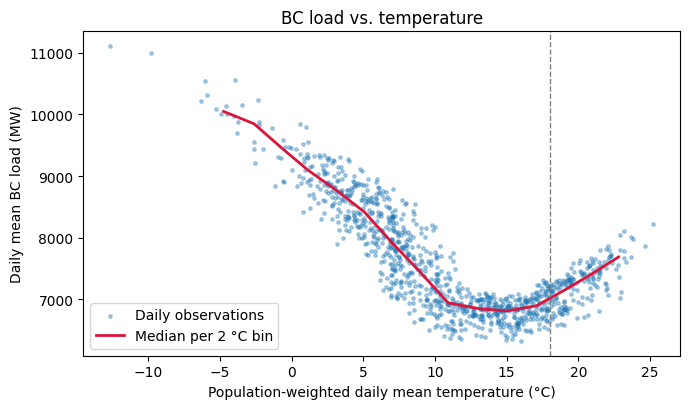

Correlation of daily load with temperature on days below 18 °C: -0.89  (n=862)


In [10]:
def build_features(load_s, wx_df):
    """Hourly feature table. wx_df must be contiguous hourly (reindexed here)."""
    idx = pd.date_range(START_TS, END_TS, freq="h")
    df = pd.DataFrame({"load_mw": load_s.reindex(idx)})
    w = wx_df.reindex(idx)
    for c in WX_VARS:
        df[c] = w[c]

    local = df.index.tz_convert("America/Vancouver")
    bc_hol = holidays.country_holidays("CA", subdiv="BC")
    df["hour"] = local.hour
    df["dow"] = local.dayofweek
    df["month"] = local.month
    df["is_holiday"] = [int(d in bc_hol) for d in local.date]
    df["t_years"] = (df.index - df.index[0]).total_seconds() / (365.25 * 86400)   # slow trend

    T = df["temperature_2m"]
    df["hdh"] = (BALANCE_TEMP_C - T).clip(lower=0)
    df["cdh"] = (T - BALANCE_TEMP_C).clip(lower=0)
    df["t_lag3"] = T.shift(3)
    df["t_roll24"] = T.rolling(24, min_periods=12).mean()
    df["naive_168"] = df["load_mw"].shift(168)       # same hour, previous week
    return df


CAL = ["hour", "dow", "month", "is_holiday", "t_years"]
TEMP = CAL + ["temperature_2m", "hdh", "cdh", "t_lag3", "t_roll24"]
FULL = TEMP + ["relative_humidity_2m", "wind_speed_10m", "shortwave_radiation"]

ds_all = build_features(load, wx)
ds = ds_all.dropna(subset=["load_mw", "naive_168"] + FULL)
print(f"Modelling table: {len(ds):,} complete hourly rows ({ds.index.min().date()} to {ds.index.max().date()})")

# Daily means in local time for the scatter
loc_date = ds.index.tz_convert("America/Vancouver").date
daily = ds.groupby(loc_date).agg(load=("load_mw", "mean"), temp=("temperature_2m", "mean"))
daily["bin"] = pd.cut(daily["temp"], bins=np.arange(-30, 40, 2))
binned = daily.groupby("bin").agg(temp=("temp", "median"), load=("load", "median"), n=("load", "size"))
binned = binned[binned.n >= 5]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(daily["temp"], daily["load"], s=6, alpha=0.35, label="Daily observations")
ax.plot(binned["temp"], binned["load"], color="crimson", lw=2, label="Median per 2 °C bin")
ax.axvline(BALANCE_TEMP_C, color="gray", ls="--", lw=1)
ax.set_xlabel("Population-weighted daily mean temperature (°C)")
ax.set_ylabel("Daily mean BC load (MW)")
ax.set_title("BC load vs. temperature")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "load_vs_temperature.png", dpi=200)
plt.show()

winter = daily[daily.temp < BALANCE_TEMP_C]
print(f"Correlation of daily load with temperature on days below {BALANCE_TEMP_C:.0f} °C: "
      f"{winter['load'].corr(winter['temp']):.2f}  (n={len(winter)})")

## 6. Baselines

Chronological split: the final `TEST_MONTHS` months are held out. Every model is scored on the same hourly rows.

- **Seasonal naive:** same hour, previous week.
- **Calendar-only:** gradient boosting on hour, weekday, month, holiday, and a slow trend.
- **Calendar + temperature:** adds temperature, heating/cooling degree-hours, and temperature lags.
- **Calendar + full weather:** adds humidity, wind, and solar radiation.

Lagged *load* is deliberately excluded from the learned models so that they reflect a day-ahead setting where yesterday's actuals are not fully known.

In [13]:
train = ds[ds.index < TEST_START]
test = ds[ds.index >= TEST_START]
print(f"Train: {len(train):,} rows | Test: {len(test):,} rows ({test.index.min().date()} to {test.index.max().date()})")


def fit_hgb(cols):
    m = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, max_leaf_nodes=31,
                                      l2_regularization=1.0, random_state=0)
    return m.fit(train[cols], train["load_mw"])


def score(y, p, index):
    y, p = np.asarray(y, float), np.asarray(p, float)
    mape = 100 * np.mean(np.abs((y - p) / y))
    rmse = float(np.sqrt(np.mean((y - p) ** 2)))
    d = pd.DataFrame({"y": y, "p": p}, index=index)
    day = d.groupby(index.tz_convert("America/Vancouver").date).max()    # daily peak (actual vs predicted)
    peak = 100 * np.mean(np.abs((day.y - day.p) / day.y))
    return dict(MAPE=mape, RMSE=rmse, Peak=peak)


models = {"Calendar-only": (fit_hgb(CAL), CAL),
          "Calendar + temperature (observed)": (fit_hgb(TEMP), TEMP),
          "Calendar + full weather (observed)": (fit_hgb(FULL), FULL)}

preds = {"Seasonal naive": test["naive_168"].values}
for name, (m, cols) in models.items():
    preds[name] = m.predict(test[cols])

results = pd.DataFrame({n: score(test["load_mw"], p, test.index) for n, p in preds.items()}).T
results.index.name = "Model"
results.to_csv("results_baselines.csv")
display(results.round(2))


Train: 15,893 rows | Test: 8,752 rows (2025-11-01 to 2026-10-31)


,MAPE,RMSE,Peak
Model,,,
Seasonal naive,4.67,505.23,5.05
Calendar-only,6.84,637.78,6.69
Calendar + temperature (observed),3.17,304.76,3.33
Calendar + full weather (observed),2.77,263.39,2.75
